# QE009: Fractons and the Shattered Hilbert Space

**What happens to a system when its particles are only allowed to move in pairs?**

In ordinary matter a particle can hop anywhere its neighbours allow. Now add one extra conservation law: not only the
total **charge** is fixed, but also the total **dipole moment** (charge × position, summed). A single charge can no
longer move by itself, because moving it would change the dipole moment. Only pairs can move, in a coordinated way.
Such restricted particles are called **fractons**.

Two surprising things follow, and this exercise computes both:

* **Part A (one exact answer, Euler-style):** the space of possible states *shatters* into a huge number of
  disconnected pieces, far more than the conservation laws alone explain. We count them exactly.
* **Part B (study):** when the system is not frozen, a bump of charge spreads out as $t^{1/4}$ instead of the usual
  $t^{1/2}$ of ordinary diffusion: **subdiffusion**. We simulate it and measure the exponent.

### Words used in this notebook

| term | meaning |
|---|---|
| **chain / site** | a row of L boxes ("sites"), numbered 0, 1, …, L−1 |
| **charge mᵢ** | the content of box i: −1, 0 or +1 (a "spin-1" in physics language) |
| **total charge** | $Q = \sum_i m_i$ |
| **dipole moment** | $P = \sum_i i \cdot m_i$: charge weighted by position, like a centre of mass |
| **conservation law** | a quantity no allowed move can change |
| **move** | a local rule that changes a few neighbouring boxes at once |
| **symmetry sector** | all states that share the same Q and P. Moves can never leave a symmetry sector |
| **fragment (Krylov sector)** | a group of states that moves can connect to each other. If a symmetry sector splits into several fragments, the system is **fragmented** |
| **frozen state** | a state where no move is possible at all: a fragment of size 1 |
| **random circuit** | a simulation where, at each time step, small groups of boxes are rearranged at random, using only allowed moves |
| **autocorrelation C(t)** | how much the charge at a site still "remembers" its starting value after time t. 1 = perfect memory, 0 = forgotten |
| **diffusion / subdiffusion** | diffusion: memory fades like $t^{-1/2}$ (ink in water). Subdiffusion: slower, here $t^{-1/4}$ |
| **hydrodynamics** | the long-time, large-scale description of a system by a few smooth fields obeying simple equations |
| **random seed** | fixes the random draws so every run gives the same numbers |

This notebook needs only `numpy`, `scipy`, `pandas` and `matplotlib`, and runs in about a minute.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
BLUE, ORANGE, GREEN, GRAY, INK = "#2a78d6", "#eb6834", "#1f9e6e", "#8a8984", "#0b0b0b"
rng = np.random.default_rng(9)                                   # random seed

## 1. The allowed moves

The basic move acts on three neighbouring boxes: two charges move apart while the middle one compensates,

$$(m_{i},\, m_{i+1},\, m_{i+2}) \;\to\; (m_{i}+1,\; m_{i+1}-2,\; m_{i+2}+1)$$

and its reverse. Check: the total charge changes by $1 - 2 + 1 = 0$, and the dipole moment by
$i - 2(i+1) + (i+2) = 0$. A move is only allowed if every box stays within $\{-1, 0, +1\}$. For example

$$(-1, +1, -1) \;\longleftrightarrow\; (0, -1, 0).$$

Later we also allow a four-box move, $(m_i, m_{i+1}, m_{i+2}, m_{i+3}) \to (m_i+1, m_{i+1}-1, m_{i+2}-1, m_{i+3}+1)$,
which also keeps both Q and P fixed.

In [2]:
MOVES_3 = [(1, -2, 1), (-1, 2, -1)]
MOVES_34 = MOVES_3 + [(1, -1, -1, 1), (-1, 1, 1, -1)]

def all_states(L):
    # every chain of length L: row k = (m_0, ..., m_{L-1}), values -1, 0, +1
    s = np.arange(3 ** L)
    return np.array([(s // 3 ** (L - 1 - i)) % 3 - 1 for i in range(L)]).T

def fragments(L, moves):
    # connect every pair of states that one move links, then find the connected pieces
    S = all_states(L); weights = 3 ** (L - 1 - np.arange(L))
    src_all, dst_all = [], []
    for mv in map(np.array, moves):
        k = len(mv)
        for i in range(L - k + 1):
            new = S[:, i:i + k] + mv
            ok = np.all(np.abs(new) <= 1, axis=1)
            src = np.nonzero(ok)[0]
            src_all.append(src); dst_all.append(src + (mv * weights[i:i + k]).sum())
    src, dst = np.concatenate(src_all), np.concatenate(dst_all)
    graph = coo_matrix((np.ones(len(src)), (src, dst)), shape=(len(S), len(S)))
    n_frag, label = connected_components(graph, directed=False)
    Q, P = S.sum(1), (S * np.arange(L)).sum(1)
    return S, n_frag, label, Q, P

S, n, label, Q, P = fragments(4, MOVES_3)
print(f"L = 4: {len(S)} states, {len(set(zip(Q, P)))} symmetry sectors, {n} fragments")

L = 4: 81 states, 49 symmetry sectors, 57 fragments


## Part A: how many pieces?

Use only the three-box move on an open chain of **L = 12** boxes ($3^{12} = 531{,}441$ states).

**Task:** count the fragments, the groups of states the moves connect, and report

$$A = \text{number of fragments for } L = 12.$$

*Check value:* for L = 6 there are **337** fragments, although only 153 different (Q, P) pairs exist.

In [3]:
_, n6, _, Q6, P6 = fragments(6, MOVES_3)
print(f"check, L = 6 : {n6} fragments, {len(set(zip(Q6, P6)))} symmetry sectors")

t0 = time.time()
S12, A, label12, Q12, P12 = fragments(12, MOVES_3)
sizes12 = np.bincount(label12)
print(f"L = 12: {len(S12):,} states, {len(set(zip(Q12, P12)))} symmetry sectors, "
      f"{(sizes12 == 1).sum():,} frozen states, largest fragment {sizes12.max()} states   ({time.time() - t0:.1f} s)")
print(f"\nANSWER  A = {A}")

check, L = 6 : 337 fragments, 153 symmetry sectors


L = 12: 531,441 states, 1169 symmetry sectors, 23,121 frozen states, largest fragment 462 states   (0.4 s)

ANSWER  A = 66921


The conservation laws alone would allow 1,169 pieces. The real number is 57 times larger, and 23,121 states cannot
move at all. This is **Hilbert-space fragmentation**: the system breaks into pieces that never talk to each other, so
it cannot reach thermal equilibrium.

### A hidden pattern

Count the fragments for every length. The numbers obey a simple rule,

$$a(L) = 2\,a(L-1) + a(L-2) + 2,$$

so they grow like $(1+\sqrt2)^L \approx 2.414^L$, the same growth as the Pell numbers. The number of symmetry sectors
only grows like $L^3$. The rule is an observation from the data below, not a proof. Proving it is a nice exercise.

In [4]:
rows = []
for L in range(3, 13):
    S, n3, lab3, Q, P = fragments(L, MOVES_3)
    _, n34, lab34, _, _ = fragments(L, MOVES_34)
    rows.append({"L": L, "states": 3 ** L, "symmetry sectors": len(set(zip(Q, P))),
                 "fragments (3-box move)": n3, "frozen (3-box)": int((np.bincount(lab3) == 1).sum()),
                 "fragments (3+4-box moves)": n34})
frag = pd.DataFrame(rows).set_index("L")
a = frag["fragments (3-box move)"]
frag["2a(L-1)+a(L-2)+2"] = (2 * a.shift(1) + a.shift(2) + 2).astype("Int64")
frag

,states,symmetry sectors,fragments (3-box move),frozen (3-box),fragments (3+4-box moves),2a(L-1)+a(L-2)+2
L,,,,,,
3,27,23,23,19,23,<NA>
4,81,49,57,41,49,<NA>
5,243,91,139,91,99,139
6,729,153,337,201,193,337
7,2187,239,815,443,367,815
8,6561,353,1969,977,689,1969
9,19683,499,4755,2155,1291,4755
10,59049,681,11481,4753,2417,11481
11,177147,903,27719,10483,4527,27719


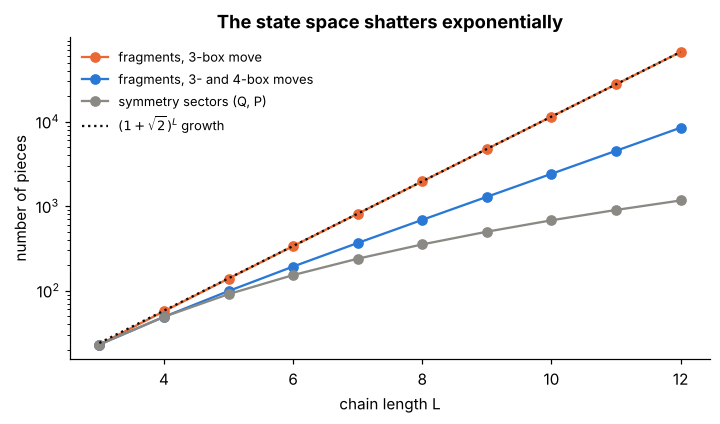

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
Ls = frag.index.values
ax.semilogy(Ls, frag["fragments (3-box move)"], "o-", color=ORANGE, label="fragments, 3-box move")
ax.semilogy(Ls, frag["fragments (3+4-box moves)"], "o-", color=BLUE, label="fragments, 3- and 4-box moves")
ax.semilogy(Ls, frag["symmetry sectors"], "o-", color=GRAY, label="symmetry sectors (Q, P)")
ax.semilogy(Ls, frag["fragments (3-box move)"].iloc[-1] * (1 + np.sqrt(2)) ** (Ls - Ls[-1]), ":", color=INK,
            label=r"$(1+\sqrt{2})^L$ growth")
ax.set_xlabel("chain length L"); ax.set_ylabel("number of pieces"); ax.legend(frameon=False, fontsize=8.5)
ax.set_title("The state space shatters exponentially"); plt.show()

The four-box move glues many pieces back together. Fragmentation remains, but it becomes **weak**: almost all states of
a symmetry sector end up in one big fragment, so the system can still relax. With only the three-box move it is
**strong**: even the biggest fragment is a vanishing part of its sector.

In [6]:
def largest_share(L, moves):
    S, n, lab, Q, P = fragments(L, moves)
    in_sector = (Q == 0) & (P == 0)                                     # sector Q = 0, P = 0
    biggest = np.bincount(lab[in_sector]).max()
    return biggest / in_sector.sum()

share = pd.DataFrame({"3-box move": [largest_share(L, MOVES_3) for L in range(6, 13, 2)],
                      "3+4-box moves": [largest_share(L, MOVES_34) for L in range(6, 13, 2)]},
                     index=pd.Index(range(6, 13, 2), name="L")).round(3)
share.columns.name = "biggest fragment / sector size (Q=0, P=0)"
share

"biggest fragment / sector size (Q=0, P=0)",3-box move,3+4-box moves
L,,
6,0.400,1.000
8,0.195,0.974
10,0.158,0.982
12,0.074,0.994


## Part B: how fast does a fractonic system forget?

**Random circuits.** Take a long chain, start from a random state, and repeatedly pick blocks of neighbouring boxes and
replace their content with a random choice among the contents allowed by the conservation laws *inside that block*.
Shift the blocks each step so information can travel. We compare three rules:

| rule | block | conserved inside block | expected memory loss |
|---|---|---|---|
| ordinary | 2 boxes | charge only | diffusion, $C(t) \sim t^{-1/2}$ |
| fracton, strong | 3 boxes | charge and dipole | frozen by fragmentation, $C(t) \to$ constant |
| fracton, weak | 4 boxes | charge and dipole | subdiffusion, $C(t) \sim t^{-1/4}$ |

**Why $t^{-1/4}$?** Ordinary diffusion obeys $\partial_t n = D\,\partial_x^2 n$: a bump spreads as $\sqrt t$.
If the dipole moment is conserved, the second-derivative term is forbidden, and the first allowed one is the fourth
derivative: $\partial_t n = -D\,\partial_x^4 n$. A bump then spreads as $t^{1/4}$, and the memory at one site fades as
$t^{-1/4}$.

In [7]:
def gate_table(k, keep_dipole):
    # for each content of a k-box block, the list of contents with the same charge (and dipole)
    D = all_states(k)
    key = D.sum(1) * 100 + ((D * np.arange(k)).sum(1) if keep_dipole else 0)
    groups = {kk: np.nonzero(key == kk)[0] for kk in np.unique(key)}
    width = max(len(g) for g in groups.values())
    table = np.zeros((3 ** k, width), int); size = np.zeros(3 ** k, int)
    for s in range(3 ** k):
        g = groups[key[s]]; table[s, :len(g)] = g; size[s] = len(g)
    return D, table, size

def autocorrelation(k, keep_dipole, L=300, samples=400, T=2000, n_times=24):
    D, table, size = gate_table(k, keep_dipole)
    weights = 3 ** (k - 1 - np.arange(k))
    times = np.unique(np.logspace(0, np.log10(T), n_times).astype(int))
    S = rng.integers(-1, 2, (samples, L)); S0 = S.copy(); C, next_i = [], 0
    for t in range(1, T + 1):
        for offset in range(k):                                         # brick-wall layers
            blocks = np.arange(offset, L - k + 1, k)[:, None] + np.arange(k)
            local = ((S[:, blocks] + 1) * weights).sum(-1)
            pick = (rng.random(local.shape) * size[local]).astype(int)
            S[:, blocks] = D[table[local, pick]]
        if next_i < len(times) and t == times[next_i]:
            C.append((S * S0).mean() / (2 / 3)); next_i += 1             # 2/3 = <m^2> at t = 0
    return times, np.array(C)

t0 = time.time()
runs = {"ordinary (2-box, charge)": autocorrelation(2, False, T=600),
        "fracton, strong (3-box)": autocorrelation(3, True, T=2000),
        "fracton, weak (4-box)": autocorrelation(4, True, T=2000)}
print(f"simulated in {time.time() - t0:.0f} s")

simulated in 24 s


In [8]:
def fit_exponent(times, C, t_min, t_max):
    m = (times >= t_min) & (times <= t_max) & (C > 0)
    return np.polyfit(np.log(times[m]), np.log(C[m]), 1)[0]

windows = {"ordinary (2-box, charge)": (5, 300), "fracton, strong (3-box)": (100, 2000),
           "fracton, weak (4-box)": (30, 2000)}
expected = {"ordinary (2-box, charge)": -0.5, "fracton, strong (3-box)": 0.0, "fracton, weak (4-box)": -0.25}
summary = pd.DataFrame({name: {"measured exponent": round(fit_exponent(*runs[name], *windows[name]), 3),
                               "theory": expected[name], "C at last time": round(runs[name][1][-1], 3)}
                        for name in runs}).T
summary

,measured exponent,theory,C at last time
"ordinary (2-box, charge)",-0.498,-0.50,0.018
"fracton, strong (3-box)",-0.002,0.00,0.348
"fracton, weak (4-box)",-0.225,-0.25,0.052


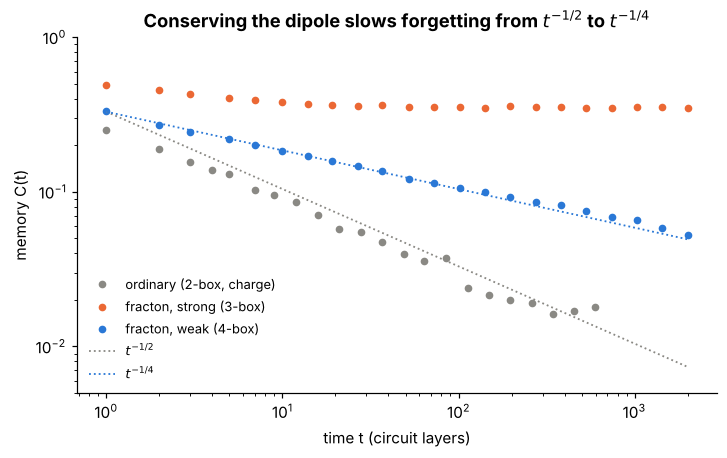

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for (name, (t, Cv)), col in zip(runs.items(), [GRAY, ORANGE, BLUE]):
    ok = Cv > 0
    ax.loglog(t[ok], Cv[ok], "o", ms=4, color=col, label=name)
tt = np.logspace(0, np.log10(2000), 50)
ax.loglog(tt, 0.33 * tt ** -0.5, ":", color=GRAY, lw=1.2, label=r"$t^{-1/2}$")
ax.loglog(tt, 0.33 * tt ** -0.25, ":", color=BLUE, lw=1.2, label=r"$t^{-1/4}$")
ax.set_xlabel("time t (circuit layers)"); ax.set_ylabel("memory C(t)")
ax.legend(frameon=False, fontsize=8.5); ax.set_ylim(5e-3, 1)
ax.set_title("Conserving the dipole slows forgetting from $t^{-1/2}$ to $t^{-1/4}$"); plt.show()

## Conclusions

1. **One extra conservation law shatters the state space.** With the three-box move, a chain of 12 boxes splits into
   **66,921** disconnected pieces, against 1,169 allowed by charge and dipole alone, and the count grows like
   $(1+\sqrt2)^L$.
2. **Strong fragmentation means no thermalisation.** With 3-box gates the memory C(t) stops decaying: the system
   remembers its starting state forever.
3. **Weak fragmentation gives fractonic hydrodynamics.** With 4-box gates the system relaxes, but slowly: the measured
   exponent is close to the predicted $-1/4$, half the ordinary diffusion exponent $-1/2$.

**Try it yourself:** add a five-box move, conserve the quadrupole moment $\sum_i i^2 m_i$ as well (theory predicts
$t^{-1/6}$), or prove the recurrence $a(L) = 2a(L-1) + a(L-2) + 2$.

### Further reading

* P. Sala, T. Rakovszky, R. Verresen, M. Knap, F. Pollmann, *Ergodicity breaking arising from Hilbert space
  fragmentation in dipole-conserving Hamiltonians*, Phys. Rev. X 10, 011047 (2020).
* V. Khemani, M. Hermele, R. Nandkishore, *Localization from Hilbert space shattering*, Phys. Rev. B 101, 174204 (2020).
* J. Feldmeier, P. Sala, G. De Tomasi, F. Pollmann, M. Knap, *Anomalous diffusion in dipole- and higher-moment
  conserving systems*, Phys. Rev. Lett. 125, 245303 (2020).
* A. Gromov, A. Lucas, R. M. Nandkishore, *Fracton hydrodynamics*, Phys. Rev. Research 2, 033124 (2020).